# Entanglement of the Actor Concept and the Gender Concept

Thesis: *Results*, section *Entanglement of the Actor Concept and the Gender Concept*.

The scores come from `src/measurement/score_entanglement.py`.

**Requirements**
- Environment: `easy-language` (`environment-easy-language.yml`)
- Packages: pandas, matplotlib, seaborn
- Data: `data/main_run/entanglement_scores.csv`, `data/main_run/mivolo_results.csv`, and for the drift checks `exports/rq1_*.csv` (in this repository)
- GPU and network: not needed

**Writes:** `figures/entanglement-coupling.pdf`, `figures/entanglement-localisation.pdf`, `figures/entanglement-correspondence.pdf`

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "corpus").is_dir())
os.chdir(ROOT)


import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D

from IPython.display import display

GSL_COLOUR, GAL_COLOUR = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#9c9b95"
STYLE = {"GSL": (GSL_COLOUR, "o"), "GAL": (GAL_COLOUR, "^")}
PANELS = {"GAL": GAL_COLOUR, "GSL": GSL_COLOUR}
LANGUAGE_FORM = {"ls": "GAL", "sd": "GSL"}
PROFESSIONS = {  # in the order of the Misersky et al. (2014) norm
    "mechaniker": "Kfz-Mechaniker", "elektriker": "Elektriker", "baecker": "Bäcker",
    "fotograf": "Fotograf", "reinigungskraft": "Reinigungskraft", "florist": "Florist",
}

## Coupling

The entanglement score of the neutral term orders the professions like the Misersky norm, although the norm enters no step of the measurement. The Fotograf is the exception in both language forms.

In [2]:
SCORES = Path("data/main_run/entanglement_scores.csv")
READOUT = Path("data/main_run/mivolo_results.csv")
COUPLING_EXPORT = Path("exports/rq1_coupling.csv")
COUPLING_PATH = Path("figures/entanglement-coupling.pdf")

BLOCK, CONDITION = "single_4", "neutral_term"
REPLICATION_BLOCK = "single_5"


ROW_OFFSET = 0.17


def load_scene_means(block: str = BLOCK, condition: str = CONDITION) -> pd.DataFrame:
    """One row per profession, language form and scene: the score averaged over the seeds."""
    readout = pd.read_csv(READOUT)
    eligible = set(readout[readout["readout_status"] == "single"]["image_id"])
    scores = pd.read_csv(SCORES)
    scores = scores[scores["image_id"].isin(eligible)].dropna(subset=["score"])
    cell = scores[(scores["layer"] == block) & (scores["condition"] == condition)].copy()
    cell["language_form"] = cell["variety"].map(LANGUAGE_FORM)
    return (cell.groupby(["profession", "language_form", "scene_label", "stereotype_value_de"])
            ["score"].agg(score="mean", n_images="size").reset_index())


def profession_means(scenes: pd.DataFrame) -> pd.DataFrame:
    """The profession mean is the mean over the scene means, as in notebook 09."""
    return (scenes.groupby(["profession", "language_form", "stereotype_value_de"])["score"]
            .agg(mean="mean", n_scenes="size", lo="min", hi="max").reset_index())


def plot_coupling(scenes: pd.DataFrame, means: pd.DataFrame, out_path: Path = COUPLING_PATH) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    fig, ax = plt.subplots(figsize=(5.8, 3.0), layout="constrained")
    rows = {key: i for i, key in enumerate(reversed(list(PROFESSIONS)))}

    for anchor in (0.0, 1.0):
        ax.axvline(anchor, color=GRID, lw=0.8, zorder=1)
    for language_form, (colour, marker) in STYLE.items():
        sign = -1 if language_form == "GSL" else 1
        points = scenes[scenes["language_form"] == language_form]
        cell = means[means["language_form"] == language_form]
        ax.plot(cell["mean"], [rows[p] + sign * ROW_OFFSET for p in cell["profession"]],
                marker, markerfacecolor="none", markeredgecolor=colour, markersize=8,
                markeredgewidth=1.4, linestyle="none", label=language_form, zorder=3)
        ax.plot(points["score"], [rows[p] + sign * ROW_OFFSET for p in points["profession"]],
                marker, color=colour, markersize=3.5, markeredgewidth=0, alpha=0.6,
                linestyle="none", zorder=4)

    ax.set_xlim(-0.25, 1.25)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.set_yticks(list(rows.values()), [PROFESSIONS[p] for p in rows])
    ax.tick_params(axis="y", length=0)
    ax.xaxis.grid(True, color=GRID, lw=0.5, alpha=0.5)
    ax.yaxis.grid(False)
    ax.set_xlabel("Entanglement score (0 = female anchor, 1 = male anchor)", color=INK)
    sns.despine(ax=ax, left=True, bottom=True)

    norm = means.drop_duplicates("profession").set_index("profession")["stereotype_value_de"]
    right = ax.secondary_yaxis("right")
    right.set_yticks(list(rows.values()), [f"{norm[p]:.2f}" for p in rows])
    right.set_ylabel("Perceived share of women\n(Misersky et al. 2014)", color=MUTED, fontsize=8)
    right.tick_params(axis="y", length=0, labelsize=8, colors=MUTED)
    sns.despine(ax=ax, right=True)

    handles = [Line2D([], [], marker=marker, linestyle="none", markersize=8,
                      markerfacecolor="none", markeredgecolor=colour, markeredgewidth=1.4,
                      label=language_form)
               for language_form, (colour, marker) in STYLE.items()]
    scene_handles = tuple(Line2D([], [], color=colour, marker=marker, linestyle="none",
                                 markersize=3.5, alpha=0.5)
                          for colour, marker in STYLE.values())
    fig.legend(handles=[*handles, scene_handles], labels=[*STYLE, "single scene"],
               handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)},
               loc="outside upper center", ncol=3, frameon=False,
               handlelength=1.0, columnspacing=1.6)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def report_coupling(scenes: pd.DataFrame, means: pd.DataFrame, block: str) -> None:
    """The numbers the subsection quotes, so figure and prose cannot drift apart."""
    table = means.pivot_table(index=["stereotype_value_de", "profession"],
                              columns="language_form", values=["mean", "n_scenes", "lo", "hi"])
    print(f"Entanglement score of the neutral term at {block}, mean over the scene means:")
    display(table.reindex(columns=["mean", "lo", "hi", "n_scenes"], level=0).round(2))

    if COUPLING_EXPORT.exists():
        export = pd.read_csv(COUPLING_EXPORT)
        export = export[export["block"] == block].assign(
            language_form=lambda d: d["variety"].map(LANGUAGE_FORM))
        check = means.merge(export, on=["profession", "language_form"])
        drift = (check["mean"] - check["mean_score_neutral_term"]).abs().max()
        print(f"\nLargest deviation from {COUPLING_EXPORT}: {drift:.4f}")
        assert drift < 1e-4, drift

    shared = (scenes.pivot_table(index=["profession", "scene_label"], columns="language_form",
                                 values="score").dropna())
    print("\nOn the scenes anchored in both language forms, professions whose scene sets differ:")
    per_profession = scenes.groupby(["profession", "language_form"])["scene_label"].agg(set)
    for profession in PROFESSIONS:
        sets = per_profession.loc[profession]
        if sets["GAL"] == sets["GSL"]:
            continue
        both = shared.loc[profession].mean().round(3)
        print(f"  {profession}: only GAL {sorted(sets['GAL'] - sets['GSL'])}, "
              f"only GSL {sorted(sets['GSL'] - sets['GAL'])}")
        print(f"  {profession}: mean over the {len(shared.loc[profession])} shared scenes "
              f"GAL {both['GAL']}, GSL {both['GSL']}")


def replication(block: str = BLOCK, other: str = REPLICATION_BLOCK) -> None:
    """The subsection reports the figure's block and owes one sentence on the replication, so the
    comparison is printed rather than left to be read off a second figure.
    """
    means = {b: profession_means(load_scene_means(b)).assign(block=b) for b in (block, other)}
    table = (pd.concat(means.values())
             .pivot_table(index=["language_form", "stereotype_value_de", "profession"],
                          columns="block", values="mean"))
    table["delta"] = table[other] - table[block]
    print(f"\n{block} against {other}:")
    display(table.round(3))
    print(f"Largest move: {table['delta'].abs().max():.3f}")
    for b, frame in means.items():
        for language_form in STYLE:
            order = (frame[frame["language_form"] == language_form]
                     .sort_values("mean", ascending=False)["profession"])
            print(f"  {language_form} {b}: {' > '.join(order)}")

Entanglement score of the neutral term at single_4, mean over the scene means:


mean          lo          hi        \
language_form                         GAL   GSL   GAL   GSL   GAL   GSL   
stereotype_value_de profession                                            
0.16                mechaniker       0.79  0.83  0.75  0.71  0.83  0.92   
0.22                elektriker       0.77  0.82  0.66  0.72  0.87  0.90   
0.41                baecker          0.32  0.24  0.05  0.05  0.70  0.38   
0.50                fotograf         0.37  0.82 -0.01  0.53  1.06  1.08   
0.75                reinigungskraft  0.11  0.20 -0.04  0.03  0.29  0.66   
0.79                florist          0.03  0.01 -0.09 -0.11  0.10  0.13   

                                    n_scenes       
language_form                            GAL  GSL  
stereotype_value_de profession                     
0.16                mechaniker           5.0  5.0  
0.22                elektriker           6.0  6.0  
0.41                baecker              6.0  6.0  
0.50                fotograf             4.0  4.0  
0.75                reinigungskraft      6.0  6.0  
0.79                florist              5.0  5.0


Largest deviation from exports/rq1_coupling.csv: 0.0000

On the scenes anchored in both language forms, professions whose scene sets differ:
  fotograf: only GAL ['foto_bearbeiten'], only GSL ['kulisse_aufbauen']
  fotograf: mean over the 3 shared scenes GAL 0.499, GSL 0.734

single_4 against single_5:


block                                              single_4  single_5  delta
language_form stereotype_value_de profession                                
GAL           0.16                mechaniker          0.792     0.791 -0.001
              0.22                elektriker          0.772     0.761 -0.011
              0.41                baecker             0.325     0.330  0.005
              0.50                fotograf            0.372     0.410  0.038
              0.75                reinigungskraft     0.107     0.081 -0.027
              0.79                florist             0.030     0.066  0.035
GSL           0.16                mechaniker          0.830     0.845  0.016
              0.22                elektriker          0.820     0.809 -0.011
              0.41                baecker             0.236     0.261  0.025
              0.50                fotograf            0.822     0.918  0.096
              0.75                reinigungskraft     0.198     0.175 -0.023
              0.79                florist             0.012     0.063  0.051

Largest move: 0.096
  GSL single_4: mechaniker > fotograf > elektriker > baecker > reinigungskraft > florist
  GAL single_4: mechaniker > elektriker > fotograf > baecker > reinigungskraft > florist
  GSL single_5: fotograf > mechaniker > elektriker > baecker > reinigungskraft > florist
  GAL single_5: mechaniker > elektriker > fotograf > baecker > reinigungskraft > florist


-> figures/entanglement-coupling.pdf


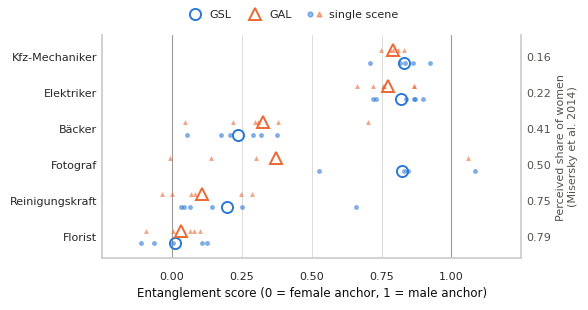

In [3]:
scenes = load_scene_means(BLOCK)
means = profession_means(scenes)
report_coupling(scenes, means, BLOCK)
replication()
plot_coupling(scenes, means, out_path=COUPLING_PATH)

## Localisation

The gap between the male- and the female-stereotyped professions is wide at every single-stream block from 0 to 10 (0.54 to 0.75 in GAL, 0.59 to 0.80 in GSL) and has no distinct peak.

In [4]:
LOCALISATION_EXPORT = Path("exports/rq1_localisation.csv")
LOCALISATION_PATH = Path("figures/entanglement-localisation.pdf")

BLOCKS = list(range(11))  # 0 to 10, the window in which the unit of the score is defined

STYLES = {"male": ("male-stereotyped", "-"), "contested": ("balanced", "--"),
          "female": ("female-stereotyped", ":")}
LABEL_GAP = 0.085  # smallest vertical distance between two labels, in score units


def load_profession_means() -> pd.DataFrame:
    """One row per block, language form and profession, along the analysis path."""
    readout = pd.read_csv(READOUT)
    eligible = set(readout[readout["readout_status"] == "single"]["image_id"])
    scores = pd.read_csv(SCORES)
    cell = scores[scores["image_id"].isin(eligible)].dropna(subset=["score"])
    cell = cell[cell["condition"] == CONDITION].copy()
    cell["language_form"] = cell["variety"].map(LANGUAGE_FORM)
    cell["block"] = cell["layer"].str.removeprefix("single_").astype(int)
    cell = cell[cell["block"].isin(BLOCKS)]
    per_scene = cell.groupby(["block", "language_form", "stereotype_direction", "profession",
                             "scene_label"])["score"].mean()
    return (per_scene.groupby(["block", "language_form", "stereotype_direction", "profession"])
            .mean().rename("score").reset_index())


def gaps(professions: pd.DataFrame) -> pd.DataFrame:
    """The stereotype gap: the male-stereotyped mean minus the female-stereotyped one."""
    groups = (professions.groupby(["block", "language_form", "stereotype_direction"])["score"]
              .mean().reset_index())
    wide = groups.pivot_table(index=["block", "language_form"], columns="stereotype_direction",
                              values="score")
    wide["gap"] = wide["male"] - wide["female"]
    return wide.reset_index()


def spread_labels(ends: dict[str, float]) -> dict[str, float]:
    """Where two lines end closer together than a label is tall, push the labels apart."""
    placed, previous = {}, None
    for label, value in sorted(ends.items(), key=lambda item: item[1]):
        if previous is not None and value < previous + LABEL_GAP:
            value = previous + LABEL_GAP
        placed[label] = previous = value
    return placed


def plot_localisation(professions: pd.DataFrame, out_path: Path = LOCALISATION_PATH) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    fig, axes = plt.subplots(1, 2, figsize=(5.8, 2.9), sharey=True, layout="constrained")

    for ax, (language_form, colour) in zip(axes, PANELS.items()):
        cell = professions[professions["language_form"] == language_form]
        ends = {}
        for profession, label in PROFESSIONS.items():
            line = cell[cell["profession"] == profession].sort_values("block")
            style = STYLES[line["stereotype_direction"].iloc[0]][1]
            ax.plot(line["block"], line["score"], linestyle=style, color=colour, linewidth=1.1,
                    zorder=3)
            ends[label] = line[line["block"] == max(BLOCKS)]["score"].iloc[0]
        for label, y in spread_labels(ends).items():
            ax.annotate(label, (max(BLOCKS) + 0.35, y), va="center", ha="left", fontsize=6.5,
                        color=colour, annotation_clip=False)
        ax.set_title(language_form, color=colour)

    axes[0].set_ylim(-0.32, 1.18)
    axes[0].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    for ax in axes:
        ax.set_xlim(-0.5, 13.5)
        ax.set_xticks([0, 2, 4, 6, 8, 10])
        ax.grid(True, color=GRID, lw=0.5, alpha=0.5)
        sns.despine(ax=ax, left=True, bottom=True)

    axes[0].set_ylabel("Entanglement score\n(0 = female anchor, 1 = male anchor)")
    fig.supxlabel("Single-stream block", fontsize=8.5, color=INK)
    handles = [Line2D([], [], color=MUTED, linestyle=style, linewidth=1.1, label=label)
               for label, style in STYLES.values()]
    fig.legend(handles=handles, loc="outside upper center", ncol=3, frameon=False,
               handlelength=2.2, columnspacing=1.6)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04, wspace=0.04)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def out_of_order() -> pd.Series:
    """Scenes per block whose anchors are no longer ordered, which is why the profile stops at 10.
    """
    scores = pd.read_csv(SCORES).dropna(subset=["anchor_gap"])
    scenes = scores.drop_duplicates(["layer", "variety", "profession", "scene_label"]).copy()
    scenes["block"] = scenes["layer"].str.removeprefix("single_").astype(int)
    scenes["language_form"] = scenes["variety"].map(LANGUAGE_FORM)
    tipped = scenes[scenes["anchor_gap"] <= 0]
    return tipped.groupby(["block", "language_form"]).size()


def report_localisation(professions: pd.DataFrame) -> None:
    """The numbers the subsection quotes, so figure and prose cannot drift apart."""
    table = gaps(professions).pivot_table(index="block",
                                     columns="language_form", values=["male", "contested",
                                                                      "female", "gap"])
    print("Entanglement score of the neutral term per stereotype group, and the gap:")
    display(table.reindex(columns=["male", "contested", "female", "gap"], level=0).round(2))
    for language_form in PANELS:
        cell = gaps(professions).query("language_form == @language_form").set_index("block")["gap"]
        print(f"  {language_form}: gap {cell.min():.2f} at block {cell.idxmin()} "
              f"to {cell.max():.2f} at block {cell.idxmax()}")

    if LOCALISATION_EXPORT.exists():
        export = pd.read_csv(LOCALISATION_EXPORT).dropna(subset=["separation_male_minus_female"])
        export = export.assign(block=export["block"].str.removeprefix("single_").astype(int),
                               language_form=export["variety"].map(LANGUAGE_FORM))
        check = gaps(professions).merge(export, on=["block", "language_form"])
        drift = (check["gap"] - check["separation_male_minus_female"]).abs().max()
        print(f"\nLargest deviation from {LOCALISATION_EXPORT}: {drift:.4f}")
        assert drift < 1e-4, drift

    print("\nScenes whose anchors are out of order, by block (blocks 0 to 10 have none):")
    display(out_of_order().rename("scenes out of order").to_frame())

Entanglement score of the neutral term per stereotype group, and the gap:

stereotype_direction  male       contested       female         gap      
language_form          GAL   GSL       GAL   GSL    GAL   GSL   GAL   GSL
block                                                                    
0                     0.86  0.90      0.58  0.75   0.12  0.10  0.75  0.80
1                     0.75  0.90      0.82  1.02   0.21  0.20  0.55  0.71
2                     0.73  0.87      0.58  0.77   0.20  0.23  0.54  0.64
3                     0.73  0.83      0.47  0.66   0.15  0.22  0.58  0.61
4                     0.78  0.82      0.35  0.53   0.07  0.10  0.71  0.72
5                     0.78  0.83      0.37  0.59   0.07  0.12  0.70  0.71
6                     0.78  0.84      0.38  0.59   0.07  0.12  0.71  0.72
7                     0.73  0.80      0.45  0.62   0.07  0.11  0.66  0.69
8                     0.77  0.84      0.57  0.70   0.15  0.21  0.62  0.63
9                     0.71  0.80      0.53  0.72   0.12  0.20  0.59  0.59
10                    0.70  0.74      0.54  0.78   0.02  0.11  0.68  0.63

  GAL: gap 0.54 at block 2 to 0.75 at block 0
  GSL: gap 0.59 at block 9 to 0.80 at block 0

Largest deviation from exports/rq1_localisation.csv: 0.0000

Scenes whose anchors are out of order, by block (blocks 0 to 10 have none):


,,scenes out of order
block,language_form,
11,GAL,1
15,GSL,1
16,GSL,1
17,GSL,1
18,GSL,1
19,GSL,1


-> figures/entanglement-localisation.pdf


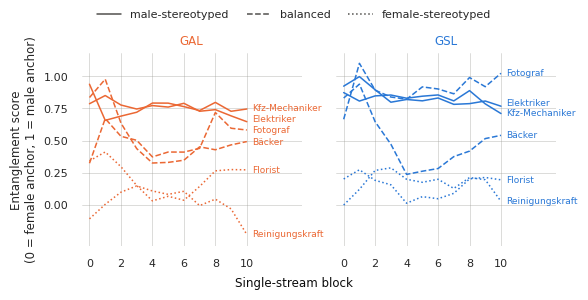

In [5]:
professions = load_profession_means()
report_localisation(professions)
plot_localisation(professions, out_path=LOCALISATION_PATH)

## Correspondence to the depicted gender

Cells with a higher entanglement score have a higher share of images read as male (Spearman's ρ = 0.92 in both language forms). The score resolves more finely than the label, which saturates at 0 and 100 %.

In [6]:
CORRESPONDENCE_EXPORT = Path("exports/rq1_correspondence.csv")
CORRESPONDENCE_PATH = Path("figures/entanglement-correspondence.pdf")


FORMS = {
    "generic_masc": ("generic masculine", "o"),
    "neutral_term": ("neutral term", "^"),
    "pair_form": ("pair form", "s"),
    "typographical": ("typographical form", "D"),
}


def load_cells(block: str = BLOCK) -> pd.DataFrame:
    """One row per profession, gender form and language form: the mean score and the share of images
    read as male, over the same images.
    """
    readout = pd.read_csv(READOUT)
    readout = readout[(readout["set"] == "test") & (readout["scene_label"] != "low_context")]
    faces = readout[readout["face_available"].astype(str) == "True"].copy()
    faces["language_form"] = faces["variety"].map(LANGUAGE_FORM)
    share = (faces.assign(male=faces["gender"] == "male")
             .groupby(["profession", "condition", "language_form"])
             .agg(share_male=("male", "mean"), n_images=("male", "size")))

    scores = pd.read_csv(SCORES)
    scores = scores[scores["image_id"].isin(set(faces["image_id"]))].dropna(subset=["score"])
    cell = scores[scores["layer"] == block].copy()
    cell["language_form"] = cell["variety"].map(LANGUAGE_FORM)
    per_scene = cell.groupby(["profession", "condition", "language_form",
                             "scene_label"])["score"].mean()
    mean_score = per_scene.groupby(["profession", "condition", "language_form"]).mean()

    cells = share.join(mean_score.rename("mean_score"), how="inner").reset_index()
    cells["share_male"] *= 100
    return cells


def spearman(cells: pd.DataFrame) -> float:
    return cells["mean_score"].corr(cells["share_male"], method="spearman")


def plot_correspondence(cells: pd.DataFrame, out_path: Path = CORRESPONDENCE_PATH) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    fig, axes = plt.subplots(1, 2, figsize=(5.8, 3.0), sharex=True, sharey=True,
                             layout="constrained")

    for ax, (language_form, colour) in zip(axes, PANELS.items()):
        panel = cells[cells["language_form"] == language_form]
        for condition, (_, marker) in FORMS.items():
            sub = panel[panel["condition"] == condition]
            ax.plot(sub["mean_score"], sub["share_male"], marker, markerfacecolor="none",
                    markeredgecolor=colour, markeredgewidth=1.1, markersize=5, linestyle="none",
                    zorder=3)
        ax.set_title(language_form, color=colour)
        ax.annotate(f"$\\rho$ = {spearman(panel):.2f}", (0.04, 0.93), xycoords="axes fraction",
                    fontsize=8, color=MUTED)
        ax.set_xlim(-0.25, 1.25)
        ax.set_xticks([0, 0.5, 1.0])
        ax.set_ylim(-8, 108)
        ax.set_yticks([0, 50, 100])
        ax.grid(True, color=GRID, lw=0.5, alpha=0.5)
        sns.despine(ax=ax, left=True, bottom=True)

    axes[0].set_ylabel("Images read as male (%)")
    fig.supxlabel("Entanglement score (0 = female anchor, 1 = male anchor)", fontsize=8.5,
                  color=INK)
    handles = [Line2D([], [], marker=marker, linestyle="none", markerfacecolor="none",
                      markeredgecolor=MUTED, markeredgewidth=1.1, markersize=5, label=label)
               for label, marker in FORMS.values()]
    fig.legend(handles=handles, loc="outside upper center", ncol=4, frameon=False,
               handlelength=1.0, columnspacing=1.4)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04, wspace=0.06)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def report_correspondence(cells: pd.DataFrame, block: str) -> None:
    """The numbers the subsection quotes, so figure and prose cannot drift apart."""
    table = cells.pivot_table(index=["condition", "profession"], columns="language_form",
                              values=["mean_score", "share_male"])
    print(f"Cells at {block}, mean score against the share read as male:")
    display(table.round(2))

    for language_form in PANELS:
        panel = cells[cells["language_form"] == language_form]
        print(f"\n{language_form}: rho over {len(panel)} cells = {spearman(panel):.3f}, "
              f"{(panel['share_male'] == 100).sum()} cells at 100 %, "
              f"{(panel['share_male'] == 0).sum()} at 0 %")
        display(pd.DataFrame([
            {"gender form": label,
             "score from": round(panel[panel["condition"] == condition]["mean_score"].min(), 2),
             "score to": round(panel[panel["condition"] == condition]["mean_score"].max(), 2),
             "share male from (%)": round(panel[panel["condition"] == condition]["share_male"].min(), 1),
             "share male to (%)": round(panel[panel["condition"] == condition]["share_male"].max(), 1)}
            for condition, (label, _) in FORMS.items()]).set_index("gender form"))

    if CORRESPONDENCE_EXPORT.exists():
        export = pd.read_csv(CORRESPONDENCE_EXPORT)
        export = export[export["block"] == block].assign(
            language_form=lambda d: d["variety"].map(LANGUAGE_FORM))
        drift = max(abs(spearman(cells[cells["language_form"] == row["language_form"]])
                        - row["spearman_rho"]) for _, row in export.iterrows())
        print(f"\nLargest deviation from {CORRESPONDENCE_EXPORT}: {drift:.4f}")
        assert drift < 1e-4, drift

Cells at single_4, mean score against the share read as male:


mean_score       share_male        
language_form                        GAL   GSL        GAL     GSL
condition     profession                                         
generic_masc  baecker               0.81  0.83     100.00  100.00
              elektriker            0.79  0.80     100.00  100.00
              florist               0.46  0.36      79.17   36.84
              fotograf              1.05  0.92     100.00  100.00
              mechaniker            0.82  0.90     100.00  100.00
              reinigungskraft       0.70  0.87     100.00  100.00
neutral_term  baecker               0.32  0.20      50.00   20.83
              elektriker            0.75  0.79     100.00  100.00
              florist               0.03  0.01       0.00    0.00
              fotograf              0.37  0.89      42.86   66.67
              mechaniker            0.80  0.83     100.00  100.00
              reinigungskraft       0.11  0.20       7.69   17.86
pair_form     baecker               0.09  0.36       0.00   43.48
              elektriker            0.15  0.18       3.57    8.00
              florist              -0.05 -0.02       0.00    0.00
              fotograf             -0.06  0.05       0.00    0.00
              mechaniker            0.12  0.20       0.00    3.70
              reinigungskraft       0.18  0.43       0.00   29.17
typographical baecker               0.57  0.62      80.77   73.33
              elektriker            0.75  0.76     100.00  100.00
              florist               0.01  0.03       7.69    0.00
              fotograf             -0.07  0.03       0.00    0.00
              mechaniker            0.75  0.84     100.00  100.00
              reinigungskraft       0.53  0.72      74.07   88.00


GAL: rho over 24 cells = 0.923, 9 cells at 100 %, 7 at 0 %


,score from,score to,share male from (%),share male to (%)
gender form,,,,
generic masculine,0.46,1.05,79.2,100.0
neutral term,0.03,0.80,0.0,100.0
pair form,-0.06,0.18,0.0,3.6
typographical form,-0.07,0.75,0.0,100.0



GSL: rho over 24 cells = 0.916, 9 cells at 100 %, 5 at 0 %


,score from,score to,share male from (%),share male to (%)
gender form,,,,
generic masculine,0.36,0.92,36.8,100.0
neutral term,0.01,0.89,0.0,100.0
pair form,-0.02,0.43,0.0,43.5
typographical form,0.03,0.84,0.0,100.0



Largest deviation from exports/rq1_correspondence.csv: 0.0000
single_5 GAL: rho = 0.921
single_5 GSL: rho = 0.904


-> figures/entanglement-correspondence.pdf


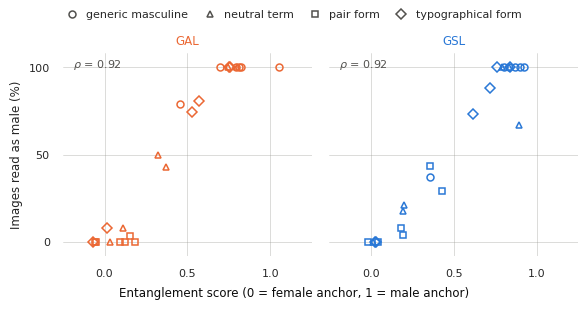

In [7]:
cells = load_cells(BLOCK)
report_correspondence(cells, BLOCK)
replication_cells = load_cells(REPLICATION_BLOCK)
for language_form in PANELS:
    panel = replication_cells[replication_cells["language_form"] == language_form]
    print(f"{REPLICATION_BLOCK} {language_form}: rho = {spearman(panel):.3f}")
plot_correspondence(cells, out_path=CORRESPONDENCE_PATH)